In [4]:
import kagglehub
import os
import pandas as pd

In [2]:
path= kagglehub.dataset_download("denizbilginn/google-maps-restaurant-reviews")

print(os.listdir(path))

100%|██████████| 657M/657M [01:22<00:00, 8.32MB/s] 

Extracting files...


['dataset', 'reviews.csv', 'sepetcioglu_restaurant', 'sepetcioglu_restaurant.csv']


In [12]:
## creato data singoli : 
df_reviews= pd.read_csv(f"{path}/reviews.csv")
df_restaurants= pd.read_csv(f"{path}/sepetcioglu_restaurant.csv")

print(df_reviews.columns.tolist())
print(df_restaurants.columns.tolist())

['business_name', 'author_name', 'text', 'photo', 'rating', 'rating_category']
['photo', 'rating', 'rating_category']


In [10]:
## vediamo cosa contegono le cartelle : 
print(os.listdir(f"{path}/dataset"))
print(os.listdir(f"{path}/sepetcioglu_restaurant"))

['dataset']
['01.png', '02.png', '03.png', '04.png', '05.png', '06.png', '07.png', '08.png', '09.png', '10.png', '11.png', '12.png', '13.png', '14.png', '15.png', '16.png', '17.png', '18.png', '19.png', '20.png', '21.png', '22.png', '23.png', '24.png', '25.png', '26.png', '27.png', '28.png', '29.png']


In [ ]:
#quante recensioni? 
df_reviews.shape

(1100, 6)

In [20]:
# quanti ristoranti?
df_reviews["business_name"].nunique()


100

In [16]:
# come sono i voti ? 
df_reviews["rating"].describe()

count    1100.000000
mean        3.912727
std         1.218459
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: rating, dtype: float64

In [18]:
#quante recensioni senza testo ? 
print(df_reviews["text"].isnull().sum())

0


In [22]:
print(df_reviews.head(5))

                     business_name    author_name  \
0  Haci'nin Yeri - Yigit Lokantasi    Gulsum Akar   
1  Haci'nin Yeri - Yigit Lokantasi  Oguzhan Cetin   
2  Haci'nin Yeri - Yigit Lokantasi     Yasin Kuyu   
3  Haci'nin Yeri - Yigit Lokantasi     Orhan Kapu   
4  Haci'nin Yeri - Yigit Lokantasi     Ozgur Sati   

                                                text  \
0  We went to Marmaris with my wife for a holiday...   
1  During my holiday in Marmaris we ate here to f...   
2  Prices are very affordable. The menu in the ph...   
3  Turkey's cheapest artisan restaurant and its f...   
4  I don't know what you will look for in terms o...   

                                               photo  rating  \
0         dataset/taste/hacinin_yeri_gulsum_akar.png       5   
1        dataset/menu/hacinin_yeri_oguzhan_cetin.png       4   
2  dataset/outdoor_atmosphere/hacinin_yeri_yasin_...       3   
3  dataset/indoor_atmosphere/hacinin_yeri_orhan_k...       5   
4           dataset/menu

In [ ]:
#quante categorie ci sono ? 
df_reviews["rating_category"].nunique()

4

In [24]:
#quali categrie ci sono ? 
df_reviews["rating_category"].unique()

<ArrowStringArray>
['taste', 'menu', 'outdoor_atmosphere', 'indoor_atmosphere']
Length: 4, dtype: str

In [25]:
#Quante recensioni ci sono per categoria ? 
df_reviews["rating_category"].value_counts()


rating_category
taste                 330
indoor_atmosphere     288
outdoor_atmosphere    286
menu                  196
Name: count, dtype: int64

In [26]:
#Controllo incrociato : che voti numerici ci sono dietro ogni categoria ? 
df_reviews.groupby("rating_category")["rating"].describe()

,count,mean,std,min,25%,50%,75%,max
rating_category,,,,,,,,
indoor_atmosphere,288.0,3.958333,1.259805,1.0,3.0,4.0,5.0,5.0
menu,196.0,3.688776,1.232082,1.0,3.0,4.0,5.0,5.0
outdoor_atmosphere,286.0,3.986014,1.139320,1.0,3.0,4.0,5.0,5.0
taste,330.0,3.942424,1.230200,1.0,3.0,4.0,5.0,5.0


In [27]:
def sentiment(r):
    if r>=4: return "positiva"
    if r==3: return "neutra"
    return "negativa"

In [28]:
df_reviews["sentiment"]= df_reviews["rating"].apply(sentiment)
df_reviews["sentiment"].value_counts()

sentiment
positiva    776
neutra      172
negativa    152
Name: count, dtype: int64

In [ ]:
# il sentiment cambi a seconda dell'aspetto ? 
pd.crosstab(df_reviews["rating_category"], df_reviews["sentiment"])

sentiment,negativa,neutra,positiva
rating_category,,,
indoor_atmosphere,41,33,214
menu,32,38,126
outdoor_atmosphere,30,52,204
taste,49,49,232


In [30]:
pd.crosstab(df_reviews["rating_category"], df_reviews["sentiment"], normalize="index")*100

sentiment,negativa,neutra,positiva
rating_category,,,
indoor_atmosphere,14.236111,11.458333,74.305556
menu,16.326531,19.387755,64.285714
outdoor_atmosphere,10.489510,18.181818,71.328671
taste,14.848485,14.848485,70.303030


<Axes: title={'center': 'Sentiment per categoria di recensione (%)'}, xlabel='Aspetto', ylabel='Quota'>

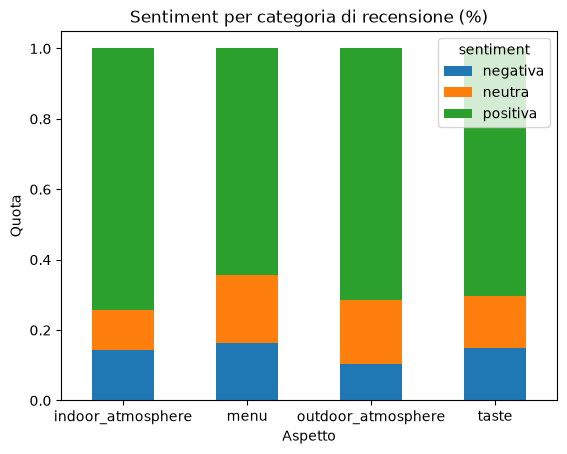

In [31]:
ct= pd.crosstab(df_reviews["rating_category"], df_reviews["sentiment"], normalize="index")

ct.plot(kind="bar", stacked=True, title="Sentiment per categoria di recensione (%)", ylabel="Quota", xlabel="Aspetto", rot=0)

In [35]:
df_reviews[df_reviews["rating_category"]=="menu"].groupby("business_name")["rating"].mean().sort_values().head(10)

business_name
Flash                      1.0
Medeniyetler Sofrasi       1.0
Fikret Balik Restaurant    2.0
Ege Vera                   2.0
Miss Pizza                 2.0
Popeyes                    2.0
Cemo Etliekmek             2.5
Imam Cagdas                2.5
Kadineli                   2.5
KFC                        2.5
Name: rating, dtype: float64

In [38]:
menu = df_reviews[df_reviews["rating_category"]=="menu"]
stats_menu=menu.groupby("business_name")["rating"].agg(media="mean", n_recensioni="count") 
print(stats_menu.sort_values("media").head(20))

                         media  n_recensioni
business_name                               
Flash                      1.0             1
Medeniyetler Sofrasi       1.0             2
Fikret Balik Restaurant    2.0             2
Ege Vera                   2.0             2
Miss Pizza                 2.0             2
Popeyes                    2.0             2
Cemo Etliekmek             2.5             2
Imam Cagdas                2.5             2
Kadineli                   2.5             2
KFC                        2.5             2
Leman Kultur               2.5             2
Koco Restaurant            2.5             2
Inegol Restaurant          2.5             2
Mcdonalds Fethiye          2.5             2
Minoa                      2.5             2
Baskent Aspava             2.5             2
Riviera                    2.5             2
Tavuk Dunyasi              2.5             2
Kasikla Restaurant         3.0             2
Starbucks Bodrum           3.0             1


In [39]:
neg_menu= df_reviews[(df_reviews["rating_category"]=="menu") & (df_reviews["sentiment"]=="negativa")]

In [40]:
print(len(neg_menu))

32


In [ ]:
for t in neg_menu["text"].head(10):
    print   ("-",t[:300]) # primi 300 caratteri  

- It was very expensive, but taste wasn't bad.
- The restaurant that made our four-day Gaziantep holiday poison! There is already excessive noise; it is impossible to hear the person next to you. The waiters are indifferent; the order takes too long to arrive.
- There was a hair in the fries; disgusting.
- We wanted mint lemonade; they put mint syrup in the lemonade; when we asked; they said that's what we do; but if you don't like it; we'll change it and they changed it.
- I think it came with a change in taste with the price update.
- Interest was good; but doner was a complete disaster. First of all; it came cold; there was no proper sauce in it; there was so much onion that I could not taste the meat at all.
- Prices are high; even for the yogurt we didn't order; we were charged.
- I don't understand what kind of business it is to sell boza in a foam glass. Offering chickpeas is a tradition next to the spoiler; but in Vefa you have to go and buy it yourself from the shop on the opp

In [43]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

In [ ]:
testo= "".join(neg_menu["text"].str.lower()) ## unisco le recensioni negative manù in testo unico, in minuscolo
parole=re.findall(r"[a-z]+",testo)  ## estraggo solo le parole ( niente punteggiatura/numeri)

parole_utili=[p for p in parole if p not in ENGLISH_STOP_WORDS and len(p)>2]  ##   3. Tolgo le stop words inglesi (the, is, and...) e le parole troppo corte

In [60]:
conteggio= Counter(parole_utili)
print(conteggio.most_common(20))

[('service', 8), ('don', 7), ('good', 7), ('food', 6), ('taste', 5), ('expensive', 4), ('order', 4), ('came', 4), ('prices', 4), ('place', 4), ('waiters', 3), ('think', 3), ('price', 3), ('sauce', 3), ('business', 3), ('ordered', 3), ('portion', 3), ('nice', 3), ('smoothie', 3), ('wasn', 2)]


In [63]:
bigrammi = Counter(zip(parole_utili, parole_utili[1:]))

for coppia, n in bigrammi.most_common(15):
    print(n," ".join(coppia))

2 prices high
2 don understand
2 service fee
2 place nice
2 food menu
2 milkshake smoothie
1 expensive taste
1 taste wasn
1 wasn bad
1 bad restaurant
1 restaurant day
1 day gaziantep
1 gaziantep holiday
1 holiday poison
1 poison excessive
